In [ ]:
# install libraries

%pip install pandas matplotlib

In [2]:
# Open the clean places file and call it places
import pandas as pd
import matplotlib.pyplot as plt

places = pd.read_csv("../data/processed/london_places.csv")
print(places.shape)
places.head()

Matplotlib is building the font cache; this may take a moment.


(17751, 6)


,osm_id,code,fclass,name,lat,lon
0,451152,2304,pub,King of Prussia,51.600840,-0.194608
1,451153,2301,restaurant,Central Restaurant,51.602031,-0.193503
2,451154,2304,pub,The Catcher in the Rye,51.599579,-0.196028
3,451271,2304,pub,The Tally Ho,51.614104,-0.176556
4,12242503,2304,pub,Railway Bell,51.592016,0.027962


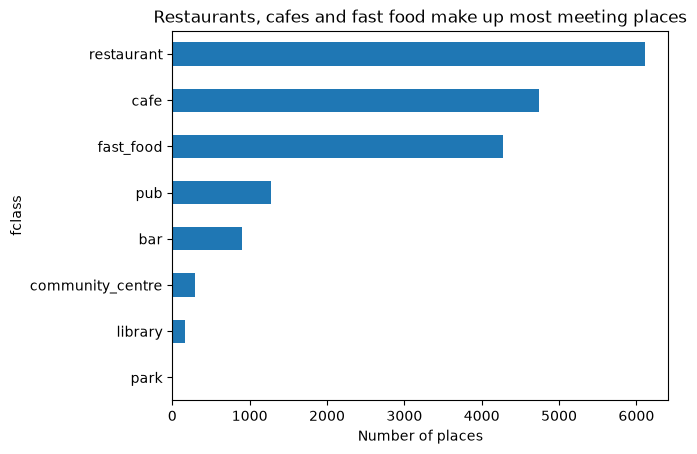

In [3]:
# how many of each type of place by using bar charts

counts = places["fclass"].value_counts(ascending=True)
counts.plot(kind="barh", title="Restaurants, cafes and fast food make up most meeting places")
plt.xlabel("Number of places")
plt.show()

Food places dominate the map. Restaurants, cafes and fast food far outnumber everything else, because London simply has many more of them than pubs, bars, libraries or community centres. Parks look almost absent, but that's a gap in this layer, since most parks are drawn as outlines rather than dots. (THIS WILL STILL BE FIXED)

We decided to take the center of London as Charing Cross (51.5073 longitude and 0.1276 latitude), and will plot some graphs to look at distances of places from center of london

In [ ]:
# straight line distance (km) from charing cross to chosen latitude and longitude
places["km_from_centre"] = (
    ((places["lat"] - 51.5073) * 111) ** 2
    + ((places["lon"] + 0.1276) * 69) ** 2
) ** 0.5

places["km_from_centre"].describe()

count    17751.000000
mean         8.323590
std          5.772231
min          0.052853
25%          3.537517
50%          7.147088
75%         12.373445
max         28.002049
Name: km_from_centre, dtype: float64

fclass
bar                  4.0
restaurant           6.0
cafe                 7.1
pub                  7.9
community_centre     8.7
fast_food            9.3
library              9.8
park                16.3
Name: km_from_centre, dtype: float64


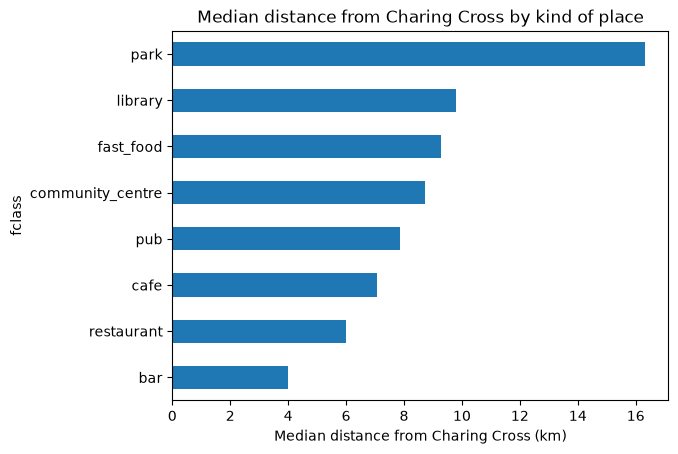

In [ ]:
# median straight line distance (km) from charing cross for each class using "km_from_centre"
by_type = places.groupby("fclass")["km_from_centre"].median().sort_values()
print(by_type.round(1))

by_type.plot(kind="barh", title="Median distance from Charing Cross by kind of place")
plt.xlabel("Median distance from Charing Cross (km)")
plt.show()

Bars and restaurants sit closest to the centre, because they cluster where offices, tourists and nightlife are, while libraries and community centres are spread out to serve local neighbourhoods. Fast food is further out than you might expect, probably because it follows high streets across the whole city, and the parks bar is too few places to trust.

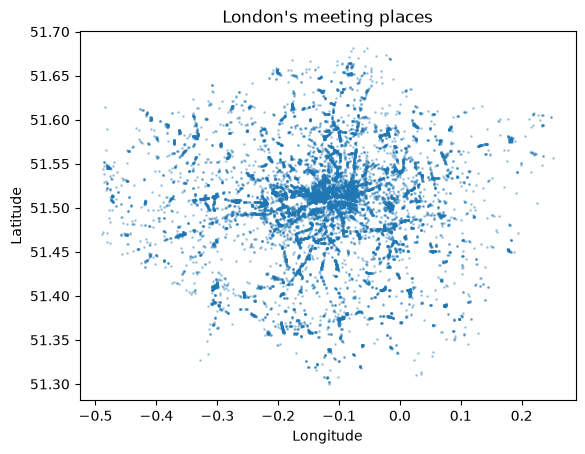

In [23]:
# map every place to visually see the spread of places across london
places.plot(kind="scatter", x="lon", y="lat", s=1, alpha=0.3,
            title="London's meeting places")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()

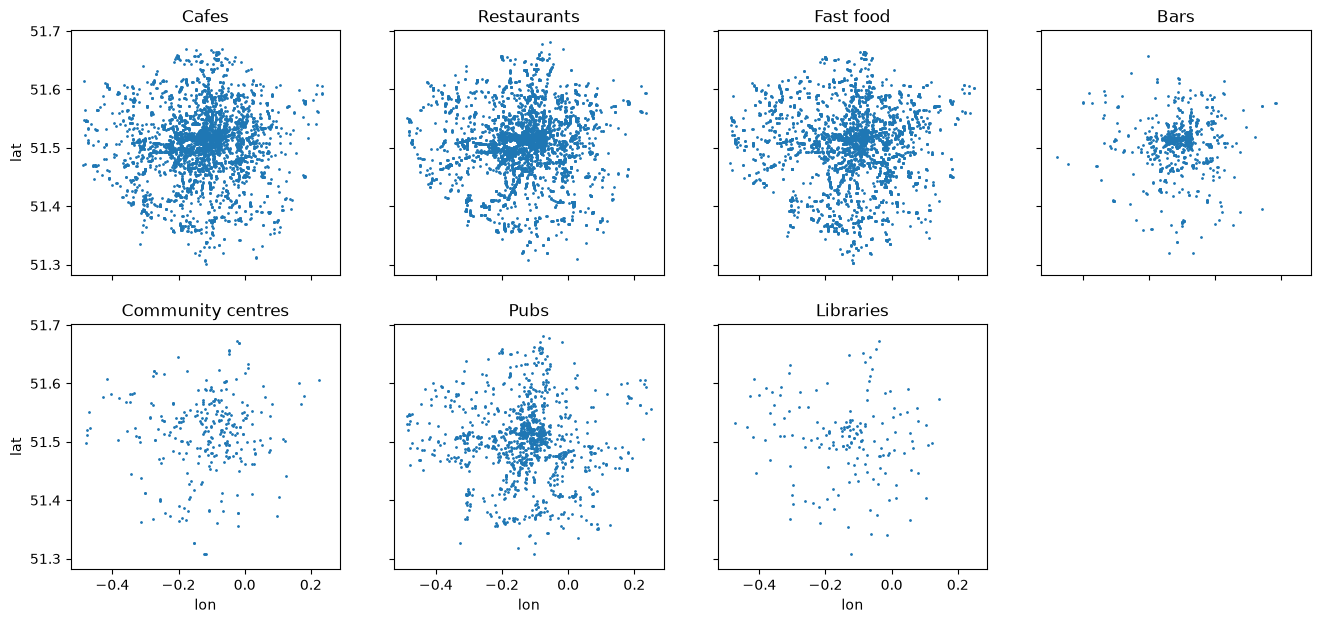

In [19]:
# one map per type of place and plotted side by side
fig, axes = plt.subplots(2, 4, figsize=(16, 7), sharex=True, sharey=True)
axes = axes.flatten()   # turn the 2x4 grid into one array from 0 to 7

places[places["fclass"] == "cafe"].plot(kind="scatter", x="lon", y="lat", s=1, ax=axes[0], title="Cafes")
places[places["fclass"] == "restaurant"].plot(kind="scatter", x="lon", y="lat", s=1, ax=axes[1], title="Restaurants")
places[places["fclass"] == "fast_food"].plot(kind="scatter", x="lon", y="lat", s=1, ax=axes[2], title="Fast food")
places[places["fclass"] == "bar"].plot(kind="scatter", x="lon", y="lat", s=1, ax=axes[3], title="Bars")
places[places["fclass"] == "community_centre"].plot(kind="scatter", x="lon", y="lat", s=1, ax=axes[4], title="Community centres")
places[places["fclass"] == "pub"].plot(kind="scatter", x="lon", y="lat", s=1, ax=axes[5], title="Pubs")
places[places["fclass"] == "library"].plot(kind="scatter", x="lon", y="lat", s=1, ax=axes[6], title="Libraries")
axes[7].axis("off")   


plt.show()

Cafes, restaurants and fast food form a dense blob in the centre, with lines of dots running outwards along the main roads and high streets where shops cluster. Bars are packed tightly into the centre with little elsewhere, while pubs keep a central cluster but also spread across the whole city. Libraries and community centres are thin and evenly scattered with no real centre, because each one serves its own local area.

In [22]:
# Work out the outlier fences for distance from the centre
q1 = places["km_from_centre"].quantile(0.25)
q3 = places["km_from_centre"].quantile(0.75)
width = q3 - q1
lower = q1 - 1.5 * width
upper = q3 + 1.5 * width

print("Box:", round(q1, 1), "to", round(q3, 1))
print("Flag below", round(lower, 1), "or above", round(upper, 1))
print("Outliers:", (places["km_from_centre"] > upper).sum())

Box: 3.5 to 12.4
Flag below -9.7 or above 25.6
Outliers: 25


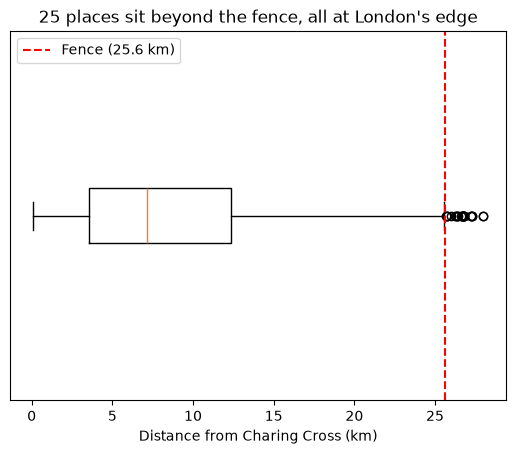

In [21]:
# Box plot of distance from the centre: dots are the outliers beyond the fence
plt.boxplot(places["km_from_centre"], orientation="horizontal")
plt.axvline(upper, color="red", linestyle="--", label=f"Fence ({upper:.1f} km)")
plt.title("25 places sit beyond the fence, all at London's edge")
plt.xlabel("Distance from Charing Cross (km)")
plt.yticks([])
plt.legend()
plt.show()

We kept all 25 outliers because they're real places on London's edge, and dropping them would give people in outer London fewer places to meet.